# 02 · Cleaning data harga PIHPS: sebelum dan sesudah

Notebook ini **menjelaskan dan memvalidasi** proses cleaning. Logikanya sendiri ada di `src/clean.py`
(dijalankan dengan `python -m src.clean` dan dites di `tests/test_clean.py`). Notebook memanggil fungsi yang sama,
sehingga tidak ada dua versi aturan yang bisa saling berbeda.

Dasar setiap aturan ada di `notebooks/01_eda.ipynb`. Ambang batasnya dibaca dari `config/config.yaml` bagian `cleaning`.

### Alur cleaning

| # | Langkah | Fungsi di `src/clean.py` | Hasil |
|---|---|---|---|
| 1 | Satu nilai per tanggal (ambil unduhan terbaru), pisahkan nasional & kota, petakan nama kota → id, lengkapi setiap seri ke semua tanggal kerja | `dedupe_latest`, `map_city_ids`, `complete_grid` | tabel panjang dengan id kota & provinsi, tanpa baris yang hilang |
| 2 | Tandai hari libur yang diisi harga sebelumnya | `detect_holiday_dates` | `is_libur_isi` → dikosongkan |
| 3 | Outlier dua tingkat, dihitung dari harga asli | `flag_outliers` | `is_outlier_flag` → dikosongkan; `is_lonjakan_tajam` → penanda saja |
| 4 | Isi celah ≤ 5 hari kerja | `fill_short_gaps` | `is_imputed` |
| 5 | Tandai harga yang lama tidak berubah | `stale_run_length` | `run_datar`, `is_usang` |

**Prinsip:** kolom `harga` (nilai asli PIHPS) tidak pernah diubah. Semua koreksi masuk ke kolom `harga_bersih`,
dan setiap koreksi punya penanda, sehingga bisa ditelusuri dan dibatalkan.

**Reproduksi:** butuh `data/raw/` (`python -m src.acquire`). Notebook ini menjalankan cleaning sendiri, sekitar 15 detik.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
from src.clean import SERI, clean, flag_outliers, map_city_ids, dedupe_latest  # noqa: E402
from src.load_raw import load_raw_long, load_regency_ref  # noqa: E402

cfg = yaml.safe_load((ROOT / "config" / "config.yaml").read_text(encoding="utf-8"))
C = cfg["cleaning"]
RAW = ROOT / cfg["paths"]["raw"]

TEAL, BLUE, ORANGE, GRAY = "#1baf7a", "#2a78d6", "#eb6834", "#a3a29c"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "figure.dpi": 110, "figure.facecolor": "white",
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

out = clean(cfg)          # fungsi yang sama dengan `python -m src.clean`
h = out["harian"]
print(f"Hasil cleaning: {len(h):,} baris kota x hari kerja | {h.kota_id.nunique()} kota/kab | "
      f"{h.tanggal.min():%Y-%m-%d} s/d {h.tanggal.max():%Y-%m-%d}")

Hasil cleaning: 535,435 baris kota x hari kerja | 62 kota/kab | 2023-07-03 s/d 2026-10-23


In [2]:
def seri_kota(jenis_pasar_id, komoditas_id, kota, mulai, selesai):
    m = ((h.jenis_pasar_id == jenis_pasar_id) & (h.komoditas_id == komoditas_id) & (h.kota == kota)
         & h.tanggal.between(mulai, selesai))
    return h[m].sort_values("tanggal")


def plot_sebelum_sesudah(ax, s, judul, tandai=None, label_tandai="", arsir=None, legend_loc="best"):
    # harga asli = garis abu putus-putus; harga bersih = garis teal; titik oranye = baris yang ditandai
    if arsir is not None:
        ax.axvspan(*arsir, color=GRAY, alpha=0.22, lw=0)
    ax.plot(s.tanggal, s.harga / 1000, color=GRAY, lw=1.6, ls="--", label="harga asli")
    ax.plot(s.tanggal, s.harga_bersih / 1000, color=TEAL, lw=2.2, label="harga bersih")
    if tandai is not None:
        t = s[tandai]
        ax.scatter(t.tanggal, t.harga / 1000, color=ORANGE, s=28, zorder=3, edgecolor="white", lw=0.8, label=label_tandai)
    ax.set_title(judul, fontsize=11)
    ax.set_ylabel("Rp ribu/kg")
    ax.set_ylim(0, np.nanmax(s.harga.to_numpy()) / 1000 * 1.15)
    rentang_hari = (s.tanggal.max() - s.tanggal.min()).days
    if rentang_hari > 75:
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    else:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %y"))
    ax.legend(frameon=False, fontsize=9, loc=legend_loc)

## 1. Dari format lebar ke tabel panjang

**Sebelum:** respons PIHPS berformat lebar (satu baris per wilayah, satu kolom per tanggal), harga berupa teks
dengan koma ribuan, dan baris kota tidak membawa id maupun provinsinya.

In [3]:
contoh_file = sorted((RAW / "pt1" / "com_16").glob("*.json"))[0]
baris = json.loads(contoh_file.read_text(encoding="utf-8"))["data"][2]
print("Contoh 1 baris mentah (dipotong):", {k: baris[k] for k in list(baris)[:7]})

Contoh 1 baris mentah (dipotong): {'no': 1, 'name': 'Kota Serang', 'level': 2, '03/07/2023': '35,500', '04/07/2023': '35,000', '05/07/2023': '35,000', '06/07/2023': '35,000'}


In [4]:
mentah = load_raw_long(RAW)
dedup = dedupe_latest(mentah)
kota_mentah = dedup[dedup.level == 2]
ref = load_regency_ref(RAW)
dipetakan = map_city_ids(kota_mentah.drop(columns="level"), ref, C["duplikat_kota_dibuang"])

pd.DataFrame({
    "baris": [len(mentah), len(dedup), len(kota_mentah), len(dipetakan), len(h)],
}, index=["semua baris mentah", "setelah buang duplikat tanggal", "baris kota saja (tanpa nasional/provinsi)",
          f"setelah buang kota duplikat id {C['duplikat_kota_dibuang']}",
          "setelah grid dilengkapi (complete_grid)"])

,baris
semua baris mentah,673596
setelah buang duplikat tanggal,673596
baris kota saja (tanpa nasional/provinsi),537791
setelah buang kota duplikat id [787],532601
setelah grid dilengkapi (complete_grid),535435


**Kenapa grid dilengkapi?** PIHPS tidak menyertakan baris sebuah kota di bulan ketika kota itu tidak punya data sama
sekali. `complete_grid` menambahkan baris kosong untuk bulan-bulan itu, sehingga data kosong terhitung dengan benar
dan pengisian celah tidak "melompati" bulan yang hilang. Langkah ini ditambahkan setelah audit pasca-cleaning.

In [5]:
per_seri_mentah = dipetakan.groupby(SERI).tanggal.nunique()
kurang = per_seri_mentah[per_seri_mentah < h.tanggal.nunique()].rename("tanggal_ada").reset_index()
kurang["tanggal_ditambahkan"] = h.tanggal.nunique() - kurang.tanggal_ada
nama = h.drop_duplicates(SERI).set_index(SERI)[["jenis_pasar", "kualitas", "kota"]]
kurang.merge(nama.reset_index(), on=SERI)[["jenis_pasar", "kualitas", "kota", "tanggal_ada", "tanggal_ditambahkan"]]

,jenis_pasar,kualitas,kota,tanggal_ada,tanggal_ditambahkan
0,Pasar Tradisional,Cabai Merah Keriting,Kab. Jember,257,608
1,Pasar Modern,Bawang Merah Ukuran Sedang,Kab. Cilacap,822,43
2,Pasar Modern,Bawang Merah Ukuran Sedang,Kab. Banyuwangi,477,388
3,Pasar Modern,Bawang Putih Ukuran Sedang,Kab. Banyuwangi,479,386
4,Pasar Modern,Cabai Rawit Merah,Kab. Banyuwangi,109,756
5,Produsen,Daging Ayam Ras Segar,Kota Blitar,212,653


**Sesudah:** satu baris = satu kota × komoditas × jenis pasar × hari kerja, dengan id kota, provinsi, nama komoditas,
dan harga numerik.

In [6]:
h[["tanggal", "jenis_pasar", "provinsi", "kota_id", "kota", "komoditas", "kualitas", "satuan", "harga",
   "harga_bersih"]].head()

,tanggal,jenis_pasar,provinsi,kota_id,kota,komoditas,kualitas,satuan,harga,harga_bersih
0,2023-07-03,Pasar Tradisional,Banten,24,Kota Serang,Telur Ayam,Telur Ayam Ras Segar,kg,31500.0,31500.0
1,2023-07-03,Pasar Tradisional,Banten,24,Kota Serang,Bawang Merah,Bawang Merah Ukuran Sedang,kg,41500.0,41500.0
2,2023-07-03,Pasar Tradisional,Banten,24,Kota Serang,Bawang Putih,Bawang Putih Ukuran Sedang,kg,44250.0,44250.0
3,2023-07-03,Pasar Tradisional,Banten,24,Kota Serang,Cabai Merah,Cabai Merah Keriting,kg,37250.0,37250.0
4,2023-07-03,Pasar Tradisional,Banten,24,Kota Serang,Cabai Rawit,Cabai Rawit Merah,kg,35500.0,35500.0


## 2. Hari libur yang diisi harga sebelumnya

`detect_holiday_dates` menandai tanggal ketika > 90% seri pasar tradisional harganya sama persis dengan hari
sebelumnya. Nilai pada tanggal itu bukan hasil pencacahan, jadi dikosongkan di `harga_bersih`.
Kalau periodenya ≤ 5 hari kerja, celahnya nanti diisi lagi (langkah 4) dengan penanda `is_imputed`.
Kalau lebih panjang, seperti Lebaran 2025, tetap kosong.

72 tanggal terdeteksi sebagai hari libur yang diisi harga sebelumnya


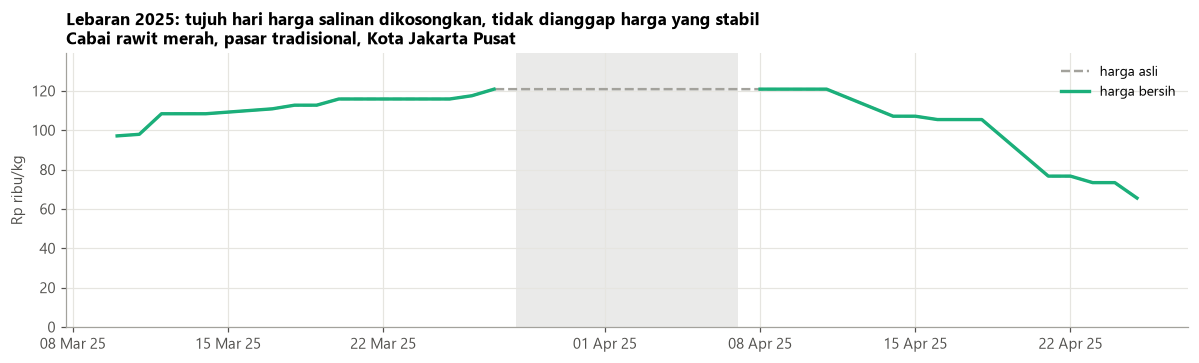

In [7]:
libur = out["libur"].tanggal
print(f"{len(libur)} tanggal terdeteksi sebagai hari libur yang diisi harga sebelumnya")
s = seri_kota(1, "com_16", "Kota Jakarta Pusat", "2025-03-10", "2025-04-25")
lib = s[s.is_libur_isi & s.tanggal.between("2025-03-25", "2025-04-10")]  # periode libur Lebaran saja
fig, ax = plt.subplots(figsize=(11, 3.4))
plot_sebelum_sesudah(ax, s, "Lebaran 2025: tujuh hari harga salinan dikosongkan, tidak dianggap harga yang stabil\n"
                     "Cabai rawit merah, pasar tradisional, Kota Jakarta Pusat",
                     arsir=(lib.tanggal.min(), lib.tanggal.max()))
plt.tight_layout(); plt.show()

> **Temuan:** Selama libur Lebaran 2025 PIHPS tidak mencatat harga, tetapi datanya tetap terisi angka yang sama.
> Setelah cleaning, minggu itu kosong. Grafik dan analisis musiman tidak akan lagi menganggap harga cabai "tenang"
> tepat saat Lebaran.

## 3. Salah input dan lonjakan tajam

`flag_outliers` memakai dua tingkat (alasan lengkap di `01_eda.ipynb` §5):

| Tingkat | Aturan | Perlakuan |
|---|---|---|
| Salah input | B: ≥ 3× / ≤ ⅓ median bergulir seri itu; C: ≥ 5× / ≤ ⅕ median kota lain di hari yang sama | `is_outlier_flag`, dikosongkan |
| Lonjakan tajam | A: menyimpang > max(5×MAD, 25%) sehari, hari sebelum & sesudah normal | `is_lonjakan_tajam`, nilai tetap dipakai |

In [8]:
ringkas = h.groupby("jenis_pasar", observed=True).agg(
    salah_input=("is_outlier_flag", "sum"), lonjakan_tajam=("is_lonjakan_tajam", "sum"))
ringkas.loc["Total"] = ringkas.sum()
ringkas

,salah_input,lonjakan_tajam
jenis_pasar,,
Pasar Modern,0,9
Pasar Tradisional,4,101
Pedagang Besar,0,3
Produsen,23,0
Total,27,113


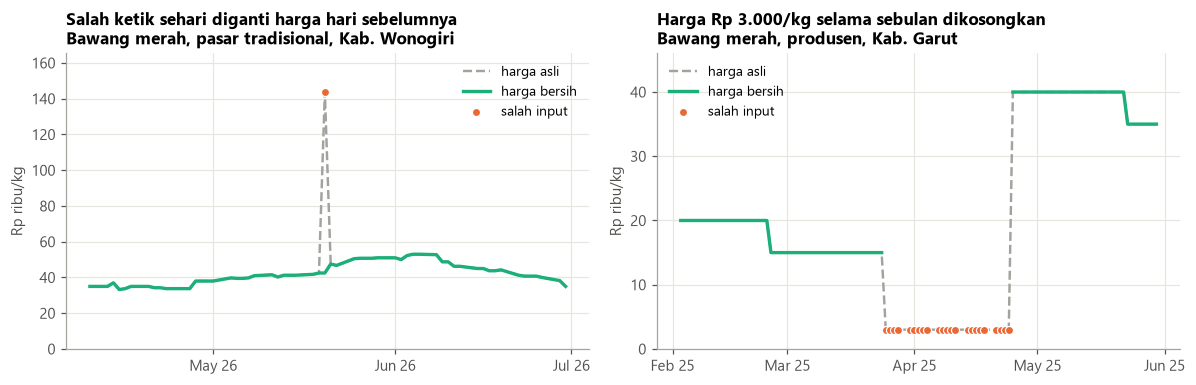

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
s1 = seri_kota(1, "com_11", "Kab. Wonogiri", "2026-04-10", "2026-06-30")
plot_sebelum_sesudah(axes[0], s1, "Salah ketik sehari diganti harga hari sebelumnya\nBawang merah, pasar tradisional, Kab. Wonogiri",
                     tandai=s1.is_outlier_flag, label_tandai="salah input")
s2 = seri_kota(4, "com_11", "Kab. Garut", "2025-02-01", "2025-05-31")
plot_sebelum_sesudah(axes[1], s2, "Harga Rp 3.000/kg selama sebulan dikosongkan\nBawang merah, produsen, Kab. Garut",
                     tandai=s2.is_outlier_flag, label_tandai="salah input")
plt.tight_layout(); plt.show()

In [10]:
h[h.is_outlier_flag].groupby(["jenis_pasar", "kualitas", "kota", "alasan_outlier"], observed=True).agg(
    hari=("tanggal", "size"), mulai=("tanggal", "min"), selesai=("tanggal", "max"), harga_asli=("harga", "median"))

hari      mulai    selesai  harga_asli
jenis_pasar       kualitas                   kota          alasan_outlier                                        
Pasar Tradisional Bawang Merah Ukuran Sedang Kab. Wonogiri rasio_ekstrem      1 2026-05-20 2026-05-20    143750.0
                  Cabai Rawit Merah          Kab. Banyumas rasio_ekstrem      1 2025-04-23 2025-04-23    258750.0
                                             Kab. Wonogiri rasio_ekstrem      1 2023-12-29 2023-12-29    232500.0
                                             Kota Sukabumi rasio_ekstrem      1 2025-12-15 2025-12-15    264250.0
Produsen          Bawang Merah Ukuran Sedang Kab. Garut    lintas_kota       23 2025-03-25 2025-04-24      3000.0

### Pelajaran dari validasi: outlier harus dihitung dari harga asli

Versi pertama `src/clean.py` menghitung outlier **setelah** hari libur dikosongkan. Hasilnya tidak cocok dengan
notebook EDA, jadi dicek ulang. Di bawah, `flag_outliers` dijalankan dengan dua masukan pada data yang sama:

In [11]:
uji = h[["jenis_pasar_id", "komoditas_id", "kota_id", "tanggal", "harga", "is_libur_isi"]].copy()
uji["harga_tanpa_libur"] = uji.harga.where(~uji.is_libur_isi)
banding = {}
for kolom, label in [("harga_tanpa_libur", "versi awal: hari libur dikosongkan dulu"),
                     ("harga", "versi final: harga asli")]:
    f = flag_outliers(uji, C["outlier"], kolom)
    banding[label] = {"salah input": int(f.is_outlier_flag.sum()), "lonjakan tajam": int(f.is_lonjakan_tajam.sum())}
    if kolom == "harga_tanpa_libur":
        versi_awal = f
pd.DataFrame(banding).T

,salah input,lonjakan tajam
versi awal: hari libur dikosongkan dulu,36,636
versi final: harga asli,27,113


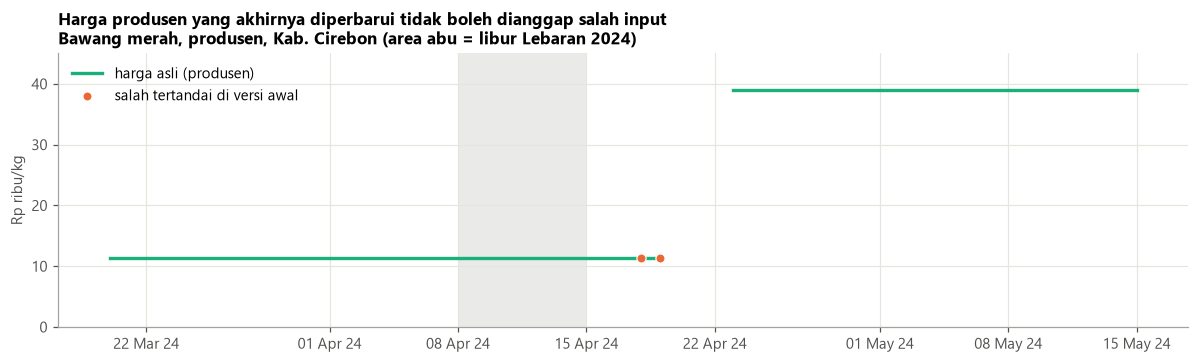

In [12]:
s = seri_kota(4, "com_11", "Kab. Cirebon", "2024-03-20", "2024-05-15")
salah = versi_awal.loc[s.index]
fig, ax = plt.subplots(figsize=(11, 3.4))
lib = s[s.is_libur_isi & s.tanggal.between("2024-04-01", "2024-04-30")]
ax.axvspan(lib.tanggal.min(), lib.tanggal.max(), color=GRAY, alpha=0.22, lw=0)
ax.plot(s.tanggal, s.harga / 1000, color=TEAL, lw=2.2, label="harga asli (produsen)")
t = s[salah.is_outlier_flag.to_numpy()]
ax.scatter(t.tanggal, t.harga / 1000, color=ORANGE, s=36, zorder=3, edgecolor="white", lw=0.8,
           label="salah tertandai di versi awal")
ax.set_ylim(0, 45); ax.set_ylabel("Rp ribu/kg"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Harga produsen yang akhirnya diperbarui tidak boleh dianggap salah input\n"
             "Bawang merah, produsen, Kab. Cirebon (area abu = libur Lebaran 2024)", fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %y"))
plt.tight_layout(); plt.show()

Harga produsen sering datar lama lalu "melompat" saat diperbarui. Jika hari libur dikosongkan dulu, jendela median
kehilangan banyak hari harga lama, sehingga median sudah condong ke harga baru. Akibatnya, hari terakhir dengan harga
lama tampak ekstrem. Salinan hari libur sendiri tidak menciptakan lonjakan (nilainya sama dengan hari sebelumnya),
jadi aman untuk perhitungan median. Versi final memakai harga asli, dan kasus ini dikunci dengan tes regresi
`test_stepped_series_with_holidays_is_not_flagged_when_using_raw_price`.

> **Temuan:** Hanya 27 titik yang benar-benar salah input dan dikosongkan. Lonjakan tajam lain tetap dipakai karena
> sering memang terjadi. Pengecekan silang dengan notebook EDA berhasil menangkap kesalahan cara hitung sebelum
> data dipakai untuk analisis.

## 4. Mengisi celah pendek

`fill_short_gaps` mengisi celah (kosong berturut-turut) ≤ 5 hari kerja dengan harga terakhir (`is_imputed`).
Celah yang lebih panjang, dan celah di awal seri, dibiarkan kosong.

In [13]:
def panjang_celah(mask):
    m = np.concatenate([[0], mask.astype(int), [0]]); d = np.diff(m)
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

hs = h.sort_values(SERI + ["tanggal"])
sebelum_isi = hs.harga.where(~hs.is_libur_isi & ~hs.is_outlier_flag).isna()  # kosong sebelum langkah isi celah
celah = np.concatenate([panjang_celah(g.to_numpy()) for _, g in sebelum_isi.groupby([hs[c] for c in SERI])])
tabel = pd.Series(celah).value_counts().sort_index()
pd.DataFrame({"jumlah celah": tabel,
              "perlakuan": ["diisi" if k <= C["gap_ffill_maks_hari"] else "tetap kosong" for k in tabel.index]}
             ).rename_axis("panjang celah (hari kerja)").T

panjang celah (hari kerja),1,2,3,4,5,6,7,8,9,10,14,15,16,19,20,21,22,23,24,29,39,69,382,631,669,777
jumlah celah,16626,8565,663,168,629,621,692,6,5,5,5,1,1,8,10,4,8,31,2,2,2,1,2,1,1,1
perlakuan,diisi,diisi,diisi,diisi,diisi,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong,tetap kosong


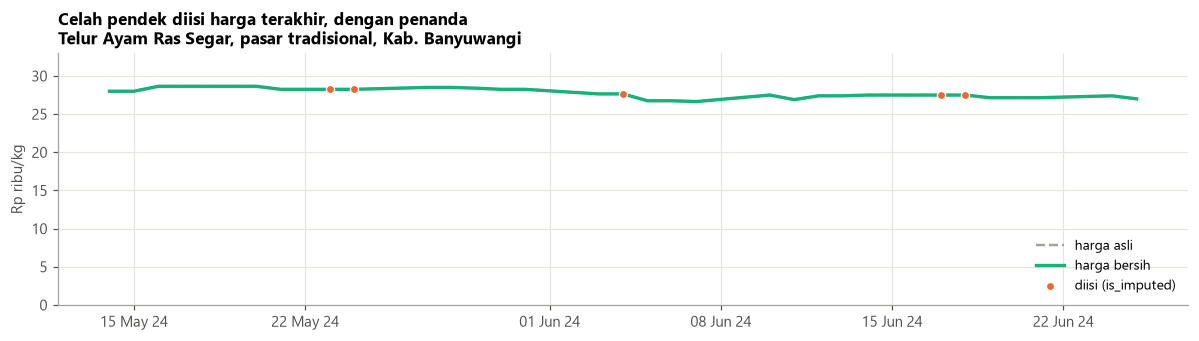

In [14]:
# contoh celah pendek yang bukan hari libur di pasar tradisional
kand = h[(h.jenis_pasar_id == 1) & h.is_imputed & ~h.is_libur_isi & ~h.is_outlier_flag]
pilih = kand.groupby(["komoditas_id", "kota"]).size().sort_values(ascending=False).index[0]
t0 = kand[(kand.komoditas_id == pilih[0]) & (kand.kota == pilih[1])].tanggal.iloc[0]
s = seri_kota(1, pilih[0], pilih[1], t0 - pd.Timedelta(days=21), t0 + pd.Timedelta(days=21))
fig, ax = plt.subplots(figsize=(11, 3.2))
plot_sebelum_sesudah(ax, s, f"Celah pendek diisi harga terakhir, dengan penanda\n{s.kualitas.iloc[0]}, pasar tradisional, {pilih[1]}",
                     tandai=s.is_imputed, label_tandai="diisi (is_imputed)", legend_loc="lower right")
imp = s[s.is_imputed]
ax.scatter(imp.tanggal, imp.harga_bersih / 1000, color=ORANGE, s=28, zorder=4, edgecolor="white", lw=0.8)
plt.tight_layout(); plt.show()

> **Temuan:** Hampir semua celah hanya 1–4 hari kerja, kebanyakan hari libur pendek, dan aman diisi. Nilai yang diisi
> tetap ditandai. **Untuk analisis mingguan (Tahap 3), median dihitung hanya dari hari dengan pencacahan nyata**, bukan
> dari nilai yang diisi.

## 5. Harga yang lama tidak berubah

`stale_run_length` menghitung berapa hari kerja berturut-turut harga sama persis. Titik dengan
`run_datar` ≥ 60 hari kerja ditandai `is_usang`. Nilainya tidak diubah. Penanda ini dipakai untuk memberi catatan
saat level harga dipakai (selisih antar kota, tambahan harga rantai pasok).

In [15]:
usang = h.pivot_table(index="kualitas", columns="jenis_pasar", values="is_usang", aggfunc="mean", observed=True) * 100
usang.round(1).style.format("{:.1f}%", na_rep="–").set_caption("% titik dengan harga tetap >= 60 hari kerja")

jenis_pasar,Pasar Modern,Pasar Tradisional,Pedagang Besar,Produsen
kualitas,,,,
Bawang Merah Ukuran Sedang,0.8%,0.0%,0.0%,0.1%
Bawang Putih Ukuran Sedang,3.6%,0.9%,4.9%,–
Cabai Merah Keriting,1.7%,0.0%,0.0%,0.2%
Cabai Rawit Merah,0.4%,0.0%,0.0%,0.0%
Daging Ayam Ras Segar,5.2%,0.0%,0.5%,2.9%
Telur Ayam Ras Segar,0.0%,0.0%,0.0%,0.2%


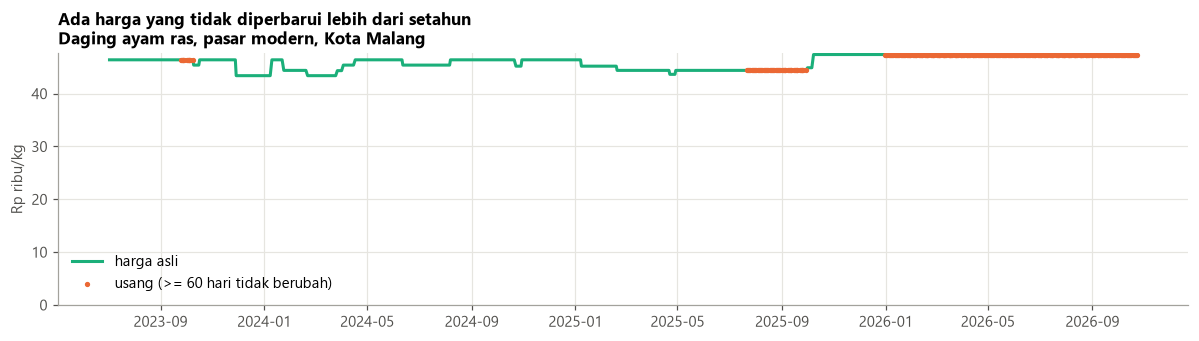

In [16]:
s = seri_kota(2, "com_7", "Kota Malang", "2023-07-01", "2026-10-31")
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(s.tanggal, s.harga / 1000, color=TEAL, lw=2, label="harga asli")
u = s[s.is_usang]
ax.scatter(u.tanggal, u.harga / 1000, color=ORANGE, s=6, zorder=3, label="usang (>= 60 hari tidak berubah)")
ax.set_ylim(bottom=0); ax.set_ylabel("Rp ribu/kg"); ax.legend(frameon=False, loc="lower left")
ax.set_title("Ada harga yang tidak diperbarui lebih dari setahun\nDaging ayam ras, pasar modern, Kota Malang", fontsize=11)
plt.tight_layout(); plt.show()

## 6. Hasil akhir: sebelum vs sesudah

In [17]:
akhir = h.groupby("jenis_pasar", observed=True).agg(
    kota=("kota_id", "nunique"),
    kosong_asli=("harga", lambda s: s.isna().mean() * 100),
    hari_libur_dikosongkan=("is_libur_isi", "mean"),
    salah_input=("is_outlier_flag", "sum"),
    diisi=("is_imputed", "sum"),
    kosong_akhir=("harga_bersih", lambda s: s.isna().mean() * 100),
    usang=("is_usang", lambda s: s.mean() * 100))
akhir["hari_libur_dikosongkan"] *= 100
akhir.style.format({"kosong_asli": "{:.2f}%", "hari_libur_dikosongkan": "{:.2f}%", "kosong_akhir": "{:.2f}%",
                    "usang": "{:.2f}%", "diisi": "{:,}"})

,kota,kosong_asli,hari_libur_dikosongkan,salah_input,diisi,kosong_akhir,usang
jenis_pasar,,,,,,,
Pasar Modern,23,4.66%,8.32%,0,"10,462",3.77%,1.92%
Pasar Tradisional,35,1.29%,8.32%,4,"12,635",1.85%,0.16%
Pedagang Besar,23,0.29%,8.32%,0,"8,142",1.59%,0.92%
Produsen,48,1.71%,8.32%,23,"8,299",3.01%,0.84%


In [18]:
q = out["kualitas"]
print(f"Tabel kualitas: {len(q)} seri (jenis pasar x komoditas x kota). Seri dengan > 10% kosong setelah cleaning:")
q[q.pct_kosong_akhir > 10][["jenis_pasar", "kualitas", "kota", "pct_kosong_asli", "pct_kosong_akhir",
                            "celah_terpanjang_akhir"]]

Tabel kualitas: 619 seri (jenis pasar x komoditas x kota). Seri dengan > 10% kosong setelah cleaning:


,jenis_pasar,kualitas,kota,pct_kosong_asli,pct_kosong_akhir,celah_terpanjang_akhir
12,Pasar Modern,Bawang Merah Ukuran Sedang,Kab. Cilacap,13.53,12.83,69
16,Pasar Modern,Bawang Merah Ukuran Sedang,Kab. Banyuwangi,64.74,65.09,382
39,Pasar Modern,Bawang Putih Ukuran Sedang,Kab. Banyuwangi,62.66,62.54,382
84,Pasar Modern,Cabai Rawit Merah,Kab. Banyuwangi,89.83,89.83,777
232,Pasar Tradisional,Cabai Merah Keriting,Kab. Jember,73.18,72.95,631
586,Produsen,Daging Ayam Ras Segar,Kota Blitar,77.46,77.34,669


In [19]:
nyata = h[(h.jenis_pasar_id == 1) & h.harga_bersih.notna() & ~h.is_imputed].copy()
nyata["minggu"] = nyata.tanggal.dt.to_period("W-FRI")
semua = pd.period_range(h.tanggal.min(), h.tanggal.max(), freq="W-FRI")
print("Minggu tanpa satu pun pencacahan nyata di pasar tradisional:",
      [str(m) for m in semua.difference(nyata.minggu.unique())])

Minggu tanpa satu pun pencacahan nyata di pasar tradisional: ['2024-04-06/2024-04-12', '2025-03-29/2025-04-04']


> **Temuan:** Setelah cleaning, data pasar tradisional hanya kosong sekitar 1,9%, termasuk minggu Lebaran yang memang
> tidak dicatat. Hanya 27 nilai yang dikoreksi karena salah input, dan semua koreksi bisa ditelusuri lewat penandanya.
> Enam seri bolong berbulan-bulan dan sebaiknya tidak dipakai untuk tren: pasar modern Kab. Banyuwangi (3 komoditas),
> cabai merah keriting pasar tradisional Kab. Jember, produsen daging ayam Kota Blitar, dan bawang merah pasar modern
> Kab. Cilacap.

## 7. Audit pasca-cleaning

Pemeriksaan independen terhadap hasil akhir, untuk menangkap hal yang lolos dari aturan cleaning. Audit ini menemukan
masalah "baris hilang" (§1) yang lalu diperbaiki dengan `complete_grid`.

### 7.1 Konsistensi penanda
Setiap koreksi harus konsisten dengan penandanya. Semua angka di bawah harus 0.

In [20]:
asli, bersih = h.harga.notna(), h.harga_bersih.notna()
normal = asli & ~h.is_libur_isi & ~h.is_outlier_flag & ~h.is_imputed
akhir_nyata = h.harga_bersih.where(~h.is_imputed).groupby([h[c] for c in SERI]).ffill()
pd.Series({
    "baris normal tapi harga_bersih kosong": int((asli & ~h.is_libur_isi & ~h.is_outlier_flag & ~bersih).sum()),
    "harga_bersih ada tanpa harga asli & tanpa is_imputed": int((~asli & bersih & ~h.is_imputed).sum()),
    "harga_bersih != harga pada baris normal": int((normal & (h.harga != h.harga_bersih)).sum()),
    "nilai isian != pengamatan nyata terakhir": int((h.is_imputed & (h.harga_bersih != akhir_nyata)).sum()),
    "salah input tanpa alasan": int((h.is_outlier_flag & (h.alasan_outlier == "")).sum()),
    "seri dengan tanggal < total hari kerja": int((h.groupby(SERI).tanggal.nunique() < h.tanggal.nunique()).sum()),
}, name="jumlah").to_frame()

,jumlah
baris normal tapi harga_bersih kosong,0
harga_bersih ada tanpa harga asli & tanpa is_imputed,0
harga_bersih != harga pada baris normal,0
nilai isian != pengamatan nyata terakhir,0
salah input tanpa alasan,0
seri dengan tanggal < total hari kerja,0


### 7.2 Jadwal pencatatan tiap jenis pasar
Persentase seri yang harganya **berubah**, per hari dalam minggu (hari libur dikeluarkan). Jika satu jenis pasar hanya
berubah pada hari tertentu, hari-hari lainnya hanyalah salinan.

In [21]:
hs = h.sort_values(SERI + ["tanggal"])
selisih = hs.groupby(SERI).harga.diff()
jadwal = (hs.assign(berubah=selisih.ne(0) & selisih.notna(), hari=hs.tanggal.dt.day_name().str[:3])
          [~hs.is_libur_isi].pivot_table(index="jenis_pasar", columns="hari", values="berubah", aggfunc="mean")
          [["Mon", "Tue", "Wed", "Thu", "Fri"]] * 100)
jadwal.columns = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat"]
jadwal.round(1).style.format("{:.1f}%").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=100)

,Senin,Selasa,Rabu,Kamis,Jumat
jenis_pasar,,,,,
Pasar Modern,0.0%,24.0%,22.9%,0.5%,0.0%
Pasar Tradisional,60.2%,40.4%,39.3%,38.7%,38.9%
Pedagang Besar,0.0%,1.9%,0.7%,66.6%,0.4%
Produsen,6.4%,2.6%,2.9%,3.0%,5.3%


> **Temuan:** Hanya pasar tradisional yang dicatat setiap hari. **Pedagang besar praktis dicatat seminggu sekali (Kamis)**,
> pasar modern pada Selasa–Rabu, dan produsen hanya sesekali. Untuk Tahap 3, harga mingguan pedagang besar, pasar modern,
> dan produsen sebaiknya memakai **nilai terakhir minggu itu**, bukan median Senin–Jumat. Median akan didominasi salinan
> harga minggu lalu, sehingga selisih harga antar kota tertinggal satu minggu.

### 7.3 Urutan harga rantai pasok
Pada kota dan hari yang sama, seberapa sering tingkat yang "lebih hulu" justru lebih mahal?

In [22]:
nyata = h[h.harga_bersih.notna() & ~h.is_imputed]
w = nyata.pivot_table(index=["kota", "kualitas", "tanggal"], columns="jenis_pasar", values="harga_bersih")
baris = []
for a, b in [("Pedagang Besar", "Pasar Tradisional"), ("Produsen", "Pedagang Besar"), ("Produsen", "Pasar Tradisional")]:
    d = w[[a, b]].dropna()
    baris.append({"perbandingan": f"{a} > {b}", "kota-hari": len(d), "persen": round((d[a] > d[b]).mean() * 100, 1)})
display(pd.DataFrame(baris))
d = w[["Pedagang Besar", "Pasar Tradisional"]].dropna()
(d["Pedagang Besar"] > d["Pasar Tradisional"]).groupby(level=[0, 1]).mean().mul(100).round(1).sort_values(
    ascending=False).head(6).rename("% hari pedagang besar > tradisional").to_frame()

,perbandingan,kota-hari,persen
0,Pedagang Besar > Pasar Tradisional,106796,5.5
1,Produsen > Pedagang Besar,28215,31.4
2,Produsen > Pasar Tradisional,51784,9.6


,,% hari pedagang besar > tradisional
kota,kualitas,
Kota Kediri,Daging Ayam Ras Segar,63.3
Kota Blitar,Daging Ayam Ras Segar,61.9
Kab. Jember,Daging Ayam Ras Segar,53.8
Kota Semarang,Daging Ayam Ras Segar,38.9
Kab. Banyuwangi,Cabai Rawit Merah,31.4
Kota Malang,Daging Ayam Ras Segar,28.0


> **Temuan:** Harga produsen lebih tinggi dari pedagang besar pada sekitar sepertiga kota-hari, kemungkinan besar karena
> harga produsen jarang diperbarui (§5). Daging ayam di beberapa kota (Kediri, Blitar, Jember) juga sering lebih mahal di
> pedagang besar daripada di pasar. Untuk analisis tambahan harga (Q5), selisih produsen → pedagang besar perlu dibaca
> sangat hati-hati dan sebaiknya memakai agregat bulanan.

### 7.4 Kasus batas yang tidak ditandai
Harga 3–5× lebih tinggi atau lebih rendah dari median kota lain. Di bawah ambang salah input (5×), jadi tidak dikosongkan.

In [23]:
med = nyata.groupby(["jenis_pasar_id", "komoditas_id", "tanggal"]).harga_bersih.transform("median")
r = nyata.harga_bersih / med
b = nyata[(r >= 3) | (r <= 1 / 3)].assign(rasio=r)
b.groupby(["jenis_pasar", "kualitas", "kota"]).agg(hari=("tanggal", "size"), mulai=("tanggal", "min"),
                                                  selesai=("tanggal", "max"), harga_median=("harga_bersih", "median"),
                                                  rasio_median=("rasio", "median")).round({"rasio_median": 2})

hari      mulai    selesai  harga_median  rasio_median
jenis_pasar  kualitas             kota                                                                   
Pasar Modern Cabai Merah Keriting Kota Blitar       138 2023-07-20 2026-09-08       20125.0          0.29
             Cabai Rawit Merah    Kab. Banyuwangi     5 2023-10-17 2023-10-23       28900.0          0.31
                                  Kota Blitar        60 2023-07-20 2025-09-09       29250.0          0.31
Produsen     Cabai Rawit Merah    Kab. Gresik        21 2024-10-25 2024-11-22        8000.0          0.31
                                  Kab. Magelang      38 2025-04-25 2025-07-24       11850.0          0.32
                                  Kab. Rembang       22 2025-04-25 2025-07-24       12150.0          0.32
                                  Kota Semarang      22 2025-04-25 2025-07-24       11450.0          0.31
                                  Kota Sukabumi      22 2025-08-25 2025-09-24       72500.0          3.92

> **Temuan:** Kasus batas hanya ada di pasar modern Kota Blitar (cabai sekitar ⅓ harga kota lain selama berbulan-bulan,
> kemungkinan dicatat per kemasan, bukan per kg) dan di produsen cabai rawit saat harga panen anjlok. Keduanya tidak
> dipakai untuk analisis utama. Pasar modern Blitar sebaiknya dikecualikan dari perbandingan harga.

### Catatan untuk Tahap 3 (feature engineering)
- Pasar tradisional: median mingguan dari **pengamatan nyata** (`harga_bersih` yang bukan `is_imputed`).
- Pedagang besar, pasar modern, produsen: **nilai nyata terakhir** dalam minggu itu (§7.2).
- Minggu dengan < 3 hari pengamatan nyata ditandai `minggu_tipis`; dua minggu Lebaran (2024, 2025) kosong total.
- Gejolak & kota penentu arah: pasar tradisional saja. Kecualikan 6 seri bolong dan pasar modern Blitar (cabai).
- Selisih vs nasional memakai `harga_nasional.parquet`.